# Type I seesaw with three active and three sterile neutrinos: where the closed form ends

$$M=\begin{pmatrix}0 & m_D\\ m_D^T & M_R\end{pmatrix},\qquad m_D\in\mathbb{C}^{3\times3},\quad M_R=\mathrm{diag}(M_1,M_2,M_3),\qquad U^TMU=\mathrm{diag}(m_1,\dots,m_6).$$

**Assumptions:** as in the rest of the series — $M_R$ diagonal and positive; real case $m_{Dij}\in\mathbb{R}$; complex case $m_{Dij}=r_{ij}e^{i\phi_{ij}}$ with $n(m-1)=6$ physical phases.

**Structure.** No massless states and $k=6$ massive ones. The masses are roots of a sextic; for two active and three sterile neutrinos, $(2,3)$, of a quintic. Polynomials of degree $\geq5$ have no general solution in radicals (Abel–Ruffini), so the *direct* symbolic diagonalization of the previous notebooks stops here. This notebook

1. shows the obstruction, and proves with a Galois-group computation that it is not an artefact of the method;
2. exhibits special textures that remain solvable;
3. shows what survives: the semi-explicit mixing matrix, the exact inverse parametrization, and the seesaw expansion.

In [1]:
import os
import sys

# Make the ``src`` package importable (the notebook lives in ``notebooks/``)
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

import numpy as np
import sympy as sp
from sympy import (symbols, solve, sin, cos, tan, sqrt, exp, I, pi, Matrix,
                   conjugate, factor, simplify, init_printing)

from src.seesaw import SymbolicSeesawTypeI
from src.matrix_utils import (symbolic_rotation_matrix, sin_cos_from_tan_fraction,
                              simplify_with_mass_ordering, seesaw_block_expansion,
                              takagi_factorization)
from src.symbolic_diagonalization import *

init_printing()
import time
import pandas as pd

## 1. The obstruction

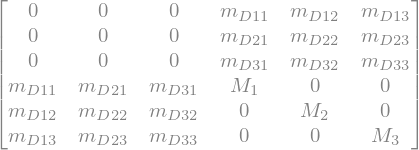

In [2]:
seesaw = SymbolicSeesawTypeI(n_generations=3, n_sterile=3, dirac='real', majorana_basis='diagonal')
mD = seesaw.m_D_sym
MR = seesaw.M_R_sym
massive = list(seesaw.massive_masses)
Mnu = seesaw.full_mass_matrix_symbolic()
Mnu

In [3]:
lamb = symbols('lambda', real=True)
charpoly = seesaw.reduced_charpoly(lamb=lamb)
charpoly.degree(), [sp.count_ops(c) for c in charpoly.all_coeffs()]

In [4]:
try:
    direct_diagonalization(seesaw, try_factor=False)
except NotSolvableInRadicals as error:
    print(error)

Irreducible polynomial of degree 6: no general solution in radicals (Abel-Ruffini). Use the semi-explicit form, the inverse parametrization or the seesaw expansion instead.


The same happens for $(2,3)$, whose reduced polynomial is a quintic:

In [5]:
seesaw23 = SymbolicSeesawTypeI(n_generations=2, n_sterile=3, dirac='real', majorana_basis='diagonal')
try:
    direct_diagonalization(seesaw23, try_factor=False)
except NotSolvableInRadicals as error:
    print(seesaw23.reduced_charpoly(lamb=lamb).degree(), '->', error)

5 -> Irreducible polynomial of degree 5: no general solution in radicals (Abel-Ruffini). Use the semi-explicit form, the inverse parametrization or the seesaw expansion instead.


### It is a genuine obstruction

A degree-$k$ polynomial is solvable in radicals iff its Galois group is solvable. Take an explicit seesaw matrix with small integer entries and compute the Galois group of its characteristic polynomial over $\mathbb{Q}$:

In [6]:
def galois_check(model, dirac_values, majorana_values):
    substitutions = {**dict(zip(list(model.m_D_sym), dirac_values)),
                     **{model.M_R_sym[i, i]: value for i, value in enumerate(majorana_values)}}
    polynomial = model.reduced_charpoly(lamb=lamb, substitutions=substitutions)
    group, _ = polynomial.galois_group(by_name=True)
    permutation_group = group.get_perm_group()
    return {'(n, m)': (model.n_gen, model.n_sterile), 'polynomial': polynomial.as_expr(),
            'irreducible': polynomial.is_irreducible, 'Galois group': group.name,
            'order': permutation_group.order(), 'solvable': permutation_group.is_solvable}

galois_33 = galois_check(seesaw, [1, 2, 3, 1, -1, 2, 2, 1, -3], [5, 7, 11])
galois_23 = galois_check(seesaw23, [1, 2, 3, 1, -1, 2], [5, 7, 11])
pd.DataFrame([galois_23, galois_33])

,"(n, m)",polynomial,irreducible,Galois group,order,solvable
0,"(2, 3)",lambda**5 - 23*lambda**4 + 147*lambda**3 - 113...,True,S5,120,False
1,"(3, 3)",lambda**6 - 23*lambda**5 + 133*lambda**4 + 83*...,True,S6,720,False


The Galois groups are the full symmetric groups $S_5$ and $S_6$, which are not solvable. Since a formula in radicals valid for all parameters would in particular solve these two instances, **no closed-form expression for the masses of the general $(2,3)$ or $(3,3)$ seesaw exists** — in any parametrization of $m_D$ and $M_R$. For comparison, the largest solvable case:

In [7]:
seesaw22 = SymbolicSeesawTypeI(n_generations=2, n_sterile=2, dirac='real', majorana_basis='diagonal')
pd.DataFrame([galois_check(seesaw22, [1, 2, 3, -1], [5, 7])])

,"(n, m)",polynomial,irreducible,Galois group,order,solvable
0,"(2, 2)",lambda**4 - 12*lambda**3 + 20*lambda**2 + 95*l...,True,S4,24,True


## 2. Special textures that remain solvable

### 2a. No inter-generation mixing

If $m_D$ is diagonal (with $M_R$ diagonal) the sextic factorizes into three one-generation quadratics; `direct_diagonalization` detects the factorization.

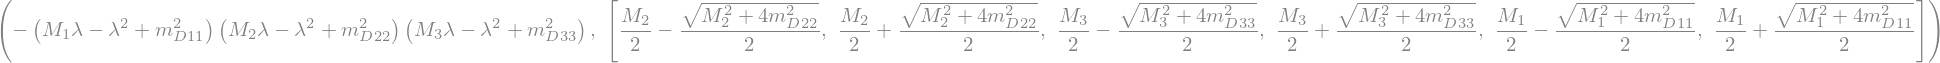

In [8]:
seesaw_diag = SymbolicSeesawTypeI(n_generations=3, n_sterile=3, dirac='real', majorana_basis='diagonal')
seesaw_diag.set_texture(dirac_texture=[(i, j) for i in range(3) for j in range(3) if i != j])
direct_diag = direct_diagonalization(seesaw_diag)
sp.factor(direct_diag['polynomial'].as_expr()), direct_diag['eigenvalues']

In [9]:
heavy_ranges = {MR[i, i]: (4.0 + 3*i, 5.0 + 3*i) for i in range(3)}
verify_takagi(direct_diag['U'], seesaw_diag.full_mass_matrix_symbolic(), direct_diag['masses'],
              n_points=3, ranges=heavy_ranges)

{'passed': True,
 'diagonalization_error': 5.5383610072219886e-15,
 'unitarity_error': 5.5398401649414165e-15,
 'mass_error': 1.7691081797653172e-16,
 'n_points': 3,
 'precision': 'double'}

### 2b. Degenerate heavy neutrinos

For $M_R=M\,\mathbb{1}$ and real $m_D$ the sextic is a cubic in $\lambda(\lambda-M)$:

$$\det(\lambda-M_\nu)=q\big(\lambda^2-M\lambda\big),\qquad q(s)=\det\big(s-m_Dm_D^T\big),$$

so $\lambda_i^{\pm}=\tfrac12\big(M\pm\sqrt{M^2+4\sigma_i^2}\big)$ with $\sigma_i$ the singular values of $m_D$ (roots of a cubic): three copies of the one-generation formula.

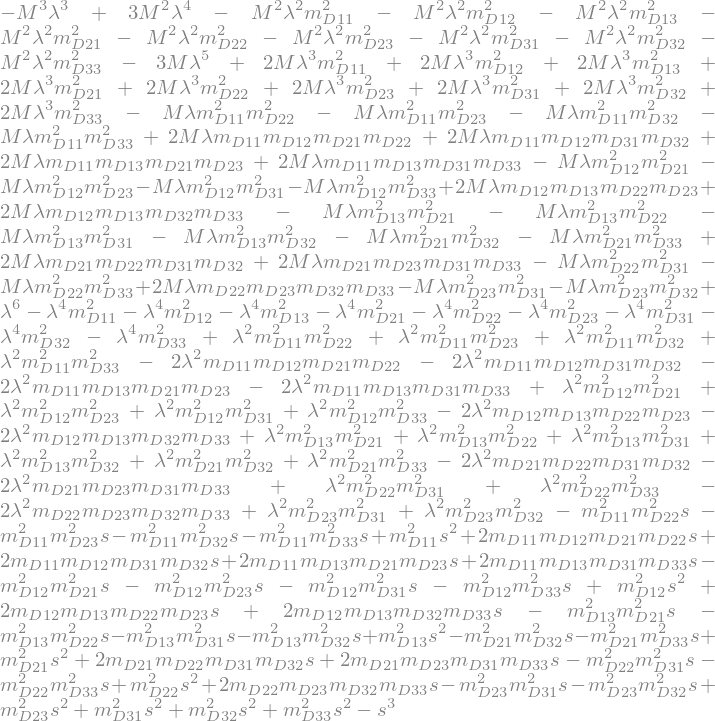

In [10]:
Mdeg = symbols('M', positive=True)
degenerate = {MR[i, i]: Mdeg for i in range(3)}
charpoly_deg = seesaw.reduced_charpoly(lamb=lamb, substitutions=degenerate)
s = symbols('s', real=True)
q = (mD*mD.T).charpoly(s)
sp.expand(charpoly_deg.as_expr() - q.as_expr().subs(s, lamb**2 - Mdeg*lamb))

In [11]:
sigma_squared = solve_reduced_charpoly(sp.Poly([sp.expand(c) for c in q.all_coeffs()], s), try_factor=False)
masses_deg = ([(sqrt(Mdeg**2 + 4*x) - Mdeg)/2 for x in sigma_squared]
              + [(sqrt(Mdeg**2 + 4*x) + Mdeg)/2 for x in sigma_squared])
evaluate = sp.lambdify(list(mD) + [Mdeg], [masses_deg, Mnu.subs(degenerate)], 'numpy')
rng = np.random.default_rng(0)
values = [complex(x) for x in rng.uniform(-1, 1, size=9)] + [5.0 + 0j]
closed_form, matrix = evaluate(*values)
numeric, _ = takagi_factorization(np.array(matrix, dtype=complex))
np.sort(np.real(closed_form)), numeric

(array([0.02192437, 0.06224681, 0.53766561, 5.02192437, 5.06224681,
        5.53766561]),
 array([0.02192437, 0.06224681, 0.53766561, 5.02192437, 5.06224681,
        5.53766561]))

## 3. What survives in the general case

### 3a. Semi-explicit mixing matrix

With the masses kept as symbols (constrained by the sextic), the mixing matrix is still a closed expression: columns of $\mathrm{adj}(M-\lambda_j)$, $\lambda_j=-m_j$ for the three light states and $+m_j$ for the heavy ones.

In [12]:
start = time.perf_counter()
semi = semi_explicit_diagonalization(seesaw)
U_semi = semi['U']
round(time.perf_counter() - start, 2), semi['eigenvalues'], expression_size(U_semi)

(4.87,
 [-m_{n_1}, -m_{n_2}, -m_{n_3}, m_{n_4}, m_{n_5}, m_{n_6}],
 {'tree': 113742, 'dag': 1932})

In [13]:
points = numeric_mass_points(seesaw, n_points=3)
verify_takagi(U_semi, Mnu, massive, points=points)

{'passed': True,
 'diagonalization_error': 1.5417712735672033e-11,
 'unitarity_error': 1.519392683320321e-11,
 'mass_error': 0.0,
 'n_points': 3,
 'precision': 'double'}

Moduli of mixing elements follow from the eigenvector–eigenvalue identity, e.g. $|U_{e1}|^2$:

In [14]:
Ue1 = eigenvector_eigenvalue_identity(Mnu, semi['eigenvalues'], 0, 0)
sp.count_ops(Ue1), float(Ue1.subs(points[0])), abs(complex(U_semi[0, 0].subs(points[0])))**2

### 3b. Exact inverse parametrization

Taking the masses as inputs avoids the sextic altogether. With $d=\mathrm{diag}(m_1,m_2,m_3)$, $D=\mathrm{diag}(m_4,m_5,m_6)$ and $O$ a (complex) orthogonal matrix,

$$X=i\,D^{-1/2}O\,d^{1/2},\qquad m_D=c_l^*X^TD\,c_h^{-1},\qquad M_R=X^*c_l^*\,d\,c_lX^\dagger+c_h^*Dc_h,$$

$c_l=(1+X^\dagger X)^{-1/2}$, $c_h=(1+XX^\dagger)^{-1/2}$. The only irrational step is the square root of the $3\times3$ matrix $1+X^\dagger X$, which needs the roots of a *cubic* — solvable. So the inverse problem for $(3,3)$ has a closed form even though the direct one does not. The attempt runs in a subprocess with a time limit; `size` is the size of the full matrix $M$ written out and `dag_size` its size as nested definitions (see `expression_size`):

In [15]:
inverse_probes = [feasibility_probe(n, m, cp, 'inverse', timeout=300)
                  for (n, m, cp) in [(2, 3, 'real'), (3, 3, 'real'), (3, 3, 'complex')]]
pd.DataFrame(inverse_probes)[['n', 'm', 'cp', 'degree', 'status', 'seconds', 'size', 'dag_size', 'verified']]

,n,m,cp,degree,status,seconds,size,dag_size,verified
0,2,3,real,5,ok,2.156802,1544089,362,True
1,3,3,real,6,ok,7.711005,453685613,821,True
2,3,3,complex,6,ok,13.176839,687781890,1159,True


For $O=\mathbb{1}$ everything decouples into three one-generation problems, $X=i\,\mathrm{diag}\big(\sqrt{m_1/m_4},\sqrt{m_2/m_5},\sqrt{m_3/m_6}\big)$:

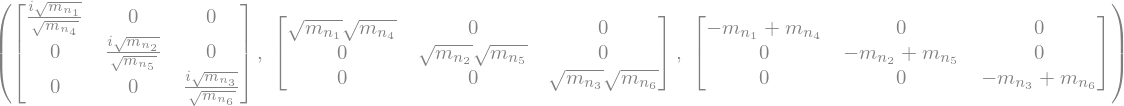

In [16]:
exact_trivial = exact_seesaw_parametrization(massive[:3], massive[3:], sp.eye(3), real=True, simplify=simplify)
exact_trivial['X'], exact_trivial['m_D'], exact_trivial['M_R']

With a general $O$ (three rotation angles) the symbolic result is built in seconds. Written out it is enormous, so it is evaluated with `lambdify_large`. Example: choose masses and angles, obtain $m_D$ and $M_R$ exactly, and recover the input masses from the full matrix.

In [16]:
theta = symbols('theta_1:4', real=True)
start = time.perf_counter()
exact33 = exact_seesaw_parametrization(massive[:3], massive[3:], orthogonal_matrix(3, theta), real=True)
round(time.perf_counter() - start, 2), expression_size(exact33['M'])

(6.72, {'tree': 453685613, 'dag': 821})

In [17]:
arguments = massive + list(theta)
values = [0.01, 0.02, 0.06, 1.0, 2.5, 4.0, 0.3, 0.8, -0.5]     # m_1..m_6, theta_1..theta_3
M_example = lambdify_large(arguments, exact33['M'])(*[complex(value) for value in values])
recovered, _ = takagi_factorization(M_example)
np.round(M_example.real, 5), np.abs(M_example.imag).max(), recovered

(array([[ 0.     ,  0.     ,  0.     ,  0.06589,  0.03289,  0.14457],
        [ 0.     ,  0.     ,  0.     ,  0.00982,  0.21021, -0.09441],
        [ 0.     ,  0.     ,  0.     , -0.18346,  0.10463,  0.29645],
        [ 0.06589,  0.00982, -0.18346,  0.96202,  0.0104 ,  0.02831],
        [ 0.03289,  0.21021,  0.10463,  0.0104 ,  2.4775 , -0.00521],
        [ 0.14457, -0.09441,  0.29645,  0.02831, -0.00521,  3.97048]]),
 np.float64(0.0),
 array([0.01, 0.02, 0.06, 1.  , 2.5 , 4.  ]))

In [18]:
mass_ranges = {symbol: (0.05 + 0.1*i, 0.1 + 0.1*i) for i, symbol in enumerate(massive[:3])}
mass_ranges.update({symbol: (2.0 + i, 2.5 + i) for i, symbol in enumerate(massive[3:])})
verify_takagi(exact33['U'], exact33['M'], massive, n_points=3, ranges=mass_ranges)

{'passed': True,
 'diagonalization_error': 3.2213078042095026e-16,
 'unitarity_error': 6.661338147750939e-16,
 'mass_error': 6.369610531643621e-16,
 'n_points': 3,
 'precision': 'double'}

### 3c. Seesaw expansion

The block diagonalization is available to any order. At leading order the light sector is the $3\times3$ real symmetric matrix $m_\nu=-m_DM_R^{-1}m_D^T$, whose eigenvalues *are* expressible in closed form (trigonometric cubic). The price is an error of relative order $\epsilon^2=(m_D/M_R)^2$, reduced to $\epsilon^4$ at next order.

In [19]:
expansion = {order: seesaw_block_expansion(mD, MR, order=order) for order in (2, 4)}
expansion[2]['m_light'][0, 0], expression_size(expansion[4]['m_light'])

(-m_D_13**2/M_3 - m_D_12**2/M_2 - m_D_11**2/M_1, {'tree': 5256, 'dag': 251})

In [20]:
mu = symbols('mu', real=True)
light_charpoly = sp.Poly([sp.together(c) for c in expansion[2]['m_light'].charpoly(mu).all_coeffs()], mu)
light_leading = [-root for root in solve_reduced_charpoly(light_charpoly, try_factor=False)][::-1]
expression_size(light_leading[0])

{'tree': 1494, 'dag': 129}

In [21]:
parameters = list(mD) + [MR[i, i] for i in range(3)]
leading_closed_form = sp.lambdify(parameters, light_leading, 'numpy')
light_matrix = {order: sp.lambdify(parameters, expansion[order]['m_light'], 'numpy') for order in expansion}
full_matrix = sp.lambdify(parameters, Mnu, 'numpy')
direction = np.random.default_rng(2).uniform(0.4, 1.6, size=9)*np.array([1, -1, 1, 1, 1, -1, -1, 1, 1])
rows = []
for eps in (0.2, 0.1, 0.05):
    values = [complex(x) for x in eps*direction] + [1.0 + 0j, 2.5 + 0j, 4.0 + 0j]
    exact_light = takagi_factorization(np.array(full_matrix(*values), dtype=complex))[0][:3]
    closed = np.sort(np.real(leading_closed_form(*values)))
    row = {'epsilon': eps, 'closed-form leading order': np.max(np.abs(closed/exact_light - 1))}
    for order in expansion:
        approx = takagi_factorization(np.array(light_matrix[order](*values), dtype=complex))[0]
        row[f'numerical O(eps^{order})'] = np.max(np.abs(approx/exact_light - 1))
    rows.append(row)
pd.DataFrame(rows)

,epsilon,closed-form leading order,numerical O(eps^2),numerical O(eps^4)
0,0.20,0.043614,0.043614,0.003996
1,0.10,0.011248,0.011248,0.000261
2,0.05,0.002835,0.002835,0.000017


The closed-form leading-order masses agree with the numerical diagonalization of $m_\nu$ at the same order, and both converge to the exact masses as $\epsilon^2$; the next order converges as $\epsilon^4$.

## Summary: the boundary of symbolic diagonalization

| $(n,m)$ | massive states $k$ | direct closed form for the masses |
|:--|:--:|:--|
| $(1,1),(2,1),(3,1)$ | 2 | quadratic |
| $(1,2)$ | 3 | cubic (trigonometric form) |
| $(2,2),(3,2),(1,3)$ | 4 | quartic (Ferrari); exact but very large |
| $(2,3)$ | 5 | **none** (Galois group $S_5$) |
| $(3,3)$ | 6 | **none** (Galois group $S_6$) |

Beyond $k=4$:

* special textures (decoupled generations, degenerate $M_R$) can still be solved;
* the mixing matrix is known in closed form *in terms of the masses* (semi-explicit form);
* the inverse problem — $m_D$ and $M_R$ from masses and mixing parameters — is solvable exactly, because it only needs the square root of a $\min(n,m)$-dimensional matrix;
* the seesaw expansion gives the light sector as a $3\times3$ problem, solvable in closed form order by order.

`seesaw_feasibility_summary.ipynb` collects timings and expression sizes for all cases.